# 7. Deciding: rebalancing, costs and the cut-off

> **In plain terms.** Rebalancing the data (class weights, SMOTE) does nothing a different cut-off can't, and it distorts the risks. What decides the cut-off is how bad a missed case is compared with an unnecessary test. At five times as bad the cut-off is 17%; it catches 33 of every 35 cases, with 30 false alarms per 100 women. The same cut-off works for every age group, which also fixes the drop in cases caught among women under 30.

Until now the project asked how well the model ranks women by risk. Screening needs a decision: at what risk do we send a woman for a follow-up test? This notebook asks three questions. Does rebalancing the data, a standard remedy when one group is smaller, help (E15)? What does each cut-off cost, once we say how bad a missed case is compared with an unnecessary test (E16)? And do different age groups need different cut-offs (E31, the fix for B12)?

New to the terms? The [glossary](../docs/GLOSSARY.md) explains every one, and the [overview](../docs/OVERVIEW.md) covers the whole project in five minutes.

In [1]:
import sys, warnings
sys.path.insert(0, "..")          # so the notebook can import the project's src/ folder
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

## 7.1 The set-up

**What we're looking for.** How lopsided the two groups are, and what the page used before this milestone.

In [2]:
import json
import numpy as np
from src.data import load_data, FEATURES
from src.modeling import current_features
from src import decision, figures

X, y = load_data()
Xc = X[current_features(FEATURES)]
m5 = json.load(open("../reports/metrics.json"))["m5"]
print("Women with diabetes:", int(y.sum()), "| without:", int((y == 0).sum()), f"| share with diabetes: {y.mean():.0%}")
print("Old rule: the highest cut-off that still catches 85% of cases =", m5["costs"]["old_cutoff"])

Women with diabetes: 268 | without: 500 | share with diabetes: 35%
Old rule: the highest cut-off that still catches 85% of cases = 0.28


**How to read it.** The counts are the whole data: 268 women with diabetes and 500 without. The old rule was set in Milestone 1: pick the highest cut-off that still catches at least 85% of the real cases.

**What it means.** The groups are lopsided but not extremely so: about one woman in three has diabetes. The 85% target was a round number chosen early, without any statement of what it costs to miss a case. This notebook replaces it with a reason.

**What's next and why.** First, the usual remedy for lopsided groups: rebalance the training data.

## 7.2 Does rebalancing help? (E15)

**What we're looking for.** Whether giving the smaller group more weight, or inventing extra training cases for it, finds more cases for the same number of false alarms.

In [3]:
reb = decision.compare_rebalancing(Xc, y)
import pandas as pd
table = pd.DataFrame(reb["table"]).T
table[["auc", "brier", "calibration_slope", "mean_risk", "sensitivity_at_half", "false_alarms_for_85"]]

,auc,brier,calibration_slope,mean_risk,sensitivity_at_half,false_alarms_for_85
Published model,0.853,0.149,0.945,0.349,0.612,154.000
Class weights,0.853,0.157,0.920,0.439,0.787,152.000
SMOTE,0.851,0.158,0.865,0.431,0.769,153.000


**How to read it.** Three versions of the published model, scored on the same 50 splits. `Class weights` makes each woman with diabetes count about twice as much as a healthy woman when the model learns. `SMOTE` (synthetic minority over-sampling) invents new cases by blending two real ones, inside each training set only, so the test women never influence it. `auc` measures ranking and `brier` measures the quality of the risks (lower is better). `mean_risk` is the average predicted risk; the real rate is 35%. `sensitivity_at_half` is the share of cases caught at a cut-off of 0.50. `false_alarms_for_85` is how many of the 500 healthy women must be flagged to catch 85% of the cases.

**What it means.** The ranking is unchanged: AUC 0.853, 0.853 and 0.851. Catching 85% of cases takes 154, 152 and 153 false alarms, a difference of two women out of 500. What changed is the risks: the average predicted risk rises from 35% to 44% and 43%, the Brier score gets worse (0.149 to 0.157 and 0.158), and the calibration slope drops. At the usual 0.50 cut-off both rebalanced models catch more cases (79% and 77%, against 61%), but that is only because they flag more women.

**What's next and why.** Check that claim directly: is a rebalanced model just the published model with a different cut-off?

## 7.3 Rebalancing is a cut-off in disguise

**What we're looking for.** Whether the published model, with its cut-off moved, reproduces what the class-weighted model does at 0.50.

In [4]:
from src.evaluate import confusion_at
published = np.array(reb["oof"]["Published model"])
rows = []
for name in ["Class weights", "SMOTE"]:
    p = np.array(reb["oof"][name])
    c = confusion_at(y, p, 0.5)
    flagged = c["tp"] + c["fp"]
    grid = np.arange(0.02, 0.9, 0.005)
    t = min(grid, key=lambda t: abs(sum(confusion_at(y, published, t)[k] for k in ("tp", "fp")) - flagged))
    d = confusion_at(y, published, t)
    rows.append({"model": name, "its cut-off": 0.5, "flags": flagged, "catches": c["tp"], "false alarms": c["fp"],
                 "published model's matching cut-off": round(t, 3), "catches (published)": d["tp"], "false alarms (published)": d["fp"]})
pd.DataFrame(rows).set_index("model")

,its cut-off,flags,catches,false alarms,published model's matching cut-off,catches (published),false alarms (published)
model,,,,,,,
Class weights,0.500,330,211,119,0.350,211,119
SMOTE,0.500,326,206,120,0.360,208,117


**How to read it.** Each row takes a rebalanced model at its cut-off of 0.50, counts how many women it flags, then finds the cut-off at which the published model flags the same number. If rebalancing found extra cases, the published model would catch fewer at that matching cut-off.

**What it means.** The class-weighted model at 0.50 flags 330 women, catching 211 with 119 false alarms. The published model with its cut-off moved to 0.35 flags the same 330 and gets the identical 211 and 119. SMOTE is within a woman or two (206 caught against 208). Rebalancing found nothing that a cut-off couldn't, and in exchange it made the risks overestimate: it is a cut-off move that also breaks the probabilities. Decision D18: the page does not rebalance.

**What's next and why.** So the cut-off is the lever. The next question is where to put it, and that needs a cost.

## 7.4 What a missed case costs (E16)

**What we're looking for.** The cut-off that is cheapest overall, once we say how bad a missed case is compared with a false alarm.

In [5]:
for r, v in m5["costs"]["ratios"].items():
    print(f"Missed case = {r}x a false alarm  ->  cut-off 1/(1+{r}) = {v['cutoff']:.2f}")
rows = []
for r, v in m5["costs"]["ratios"].items():
    rows.append({"a missed case is": f"{r}x a false alarm", "cut-off": v["cutoff"], **{k: v["per_100"][k] for k in ("tp", "fn", "fp", "tn")}})
pd.DataFrame(rows).set_index("a missed case is").rename(columns={"tp": "caught", "fn": "missed", "fp": "false alarms", "tn": "healthy, not flagged"})

Missed case = 2x a false alarm  ->  cut-off 1/(1+2) = 0.33
Missed case = 5x a false alarm  ->  cut-off 1/(1+5) = 0.17
Missed case = 10x a false alarm  ->  cut-off 1/(1+10) = 0.09


,cut-off,caught,missed,false alarms,"healthy, not flagged"
a missed case is,,,,,
2x a false alarm,0.330,28,7,17,48
5x a false alarm,0.170,33,2,30,35
10x a false alarm,0.090,34,1,39,26


**How to read it.** Suppose flagging a healthy woman costs 1 unit (an unnecessary blood test) and missing a woman with diabetes costs 2, 5 or 10 units. For a woman whose true risk is p, flagging her costs 1 - p units on average (the chance she is healthy) and not flagging her costs ratio times p. Flagging is cheaper when p is at least 1 / (1 + ratio). So the best cut-off is simply that number. The table shows what each cut-off does to every 100 women screened (35 of them have diabetes).

**What it means.** At 2 times the cut-off is 0.33: 28 of 35 cases caught, 17 false alarms. At 5 times it is 0.17: 33 caught, 30 false alarms, and 63 of every 100 women are flagged. At 10 times it is 0.09: 34 caught, 39 false alarms, 73 flagged. Each step down in cut-off catches a few more cases and flags many more healthy women. The old 85% rule (0.28) quietly assumed a missed case is only about 2.6 times as bad as a false alarm. Decision D17: the page uses 5 times, so the published cut-off is 0.17, and the three choices sit side by side on the page so a reader can pick their own.

**What's next and why.** Check the arithmetic against the data: is that cut-off really the cheapest, and how precise must it be?

## 7.5 Is the cost-based cut-off really the cheapest?

**What we're looking for.** The total cost per 100 women at every cut-off, and how much the cheapest cut-off moves when the women are resampled.

,cost-based cut-off,cheapest in this data,"cheapest, 95% range"
2,0.330,0.260,0.23 to 0.43
5,0.170,0.190,0.09 to 0.26
10,0.090,0.090,0.09 to 0.17


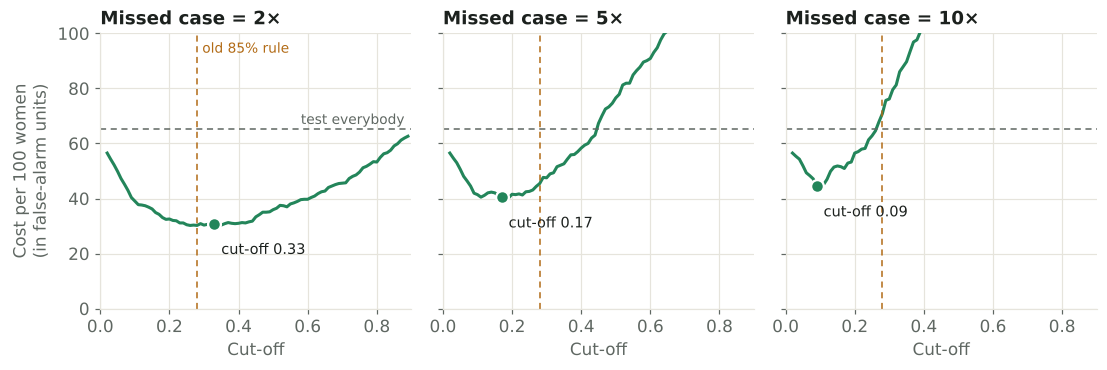

In [6]:
figures.m5_cost();
pd.DataFrame({r: {"cost-based cut-off": v["cutoff"], "cheapest in this data": v["empirical_best"]["best"],
                  "cheapest, 95% range": f"{v['empirical_best']['low']:.2f} to {v['empirical_best']['high']:.2f}"}
              for r, v in m5["costs"]["ratios"].items()}).T

**How to read it.** Each panel assumes a different cost for a missed case. The green line is the cost per 100 women at every cut-off, in false-alarm units, so lower is better. The dot marks the formula's cut-off. The table compares it with the cut-off that happens to be cheapest in this data, and the range that cut-off covers when the 768 women are resampled 1,000 times.

**What it means.** The formula's cut-off lands inside the data's 95% range in all three cases (0.33 in 0.23 to 0.43, 0.17 in 0.09 to 0.26, 0.09 in 0.09 to 0.17), so the formula and the data agree. The ranges are wide, which is the other lesson: the curves are flat near their lowest point, so a cut-off a few hundredths either side costs almost the same. The cut-off does not need to be exact, but the cost ratio matters, because the three curves have different minima.

**What's next and why.** Compare the choice with the alternatives a reader might suggest.

## 7.6 Against the alternatives

**What we're looking for.** The cost of the cost-based cut-off against testing everybody, testing nobody, the old rule and a glucose rule.

In [7]:
pd.DataFrame({f"{r}x": v["cost_per_100"] for r, v in m5["costs"]["ratios"].items()}).round(1)

,2x,5x,10x
Test nobody,69.800,174.500,349.000
Test everybody,65.100,65.100,65.100
Glucose of 140 or more,42.700,94.700,181.200
Old rule (catch 85%),30.200,45.400,70.800
Cut-off 0.50,35.900,76.600,144.300
Cost-based cut-off,30.900,40.500,44.500


**How to read it.** Cost per 100 women, in false-alarm units, for each policy at each cost ratio. Lower is better. `Cost-based cut-off` is the model with its cut-off from 7.4.

**What it means.** At 5 and 10 times the cost-based cut-off is the cheapest policy. At 5 times it costs 40, against 45 for the old rule, 65 for testing everybody, 95 for the glucose-of-140 rule and 175 for testing nobody. At 2 times the old rule is a hair cheaper (30.2 against 30.9), since 0.28 is close to 0.33; the difference is noise. The higher the cost of a missed case, the more the old rule costs: at 10 times it is 71 against 45.

**What's next and why.** The same comparison drawn the way medical decision-making papers draw it.

## 7.7 The decision curve

**What we're looking for.** Whether the model is worth using at all, compared with testing everybody or nobody, at every cut-off.

,cut-off,"net benefit, model","net benefit, test everybody"
2,0.330,0.196,0.028
5,0.170,0.267,0.216
10,0.090,0.305,0.285


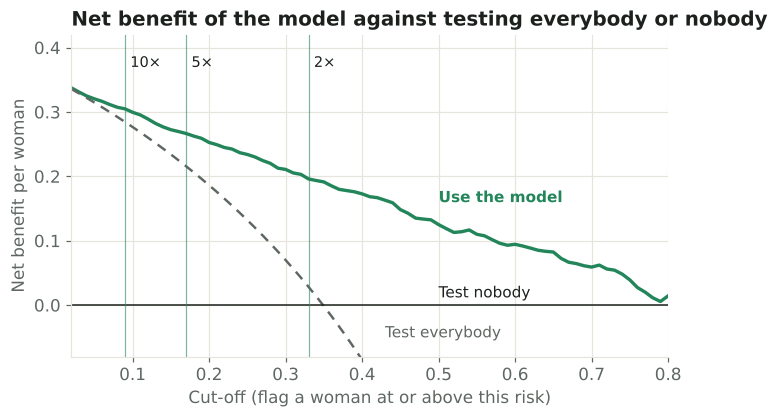

In [8]:
figures.m5_decision_curve();
pd.DataFrame({r: {"cut-off": v["cutoff"], "net benefit, model": round(v["net_benefit"], 3),
                  "net benefit, test everybody": round(v["net_benefit_all"], 3)}
              for r, v in m5["costs"]["ratios"].items()}).T

**How to read it.** Net benefit counts the cases found, minus the false alarms weighted by how costly they are relative to a missed case: net benefit = true positives per woman - false positives per woman x cut-off / (1 - cut-off). Testing nobody scores zero by definition. A model is worth using at a cut-off where its line sits above both the zero line and the dashed 'test everybody' line.

**What it means.** At each of the three chosen cut-offs the model beats testing everybody. The gap is wide at 2 times (0.196 against 0.028) and 5 times (0.267 against 0.216), and narrow at 10 times (0.305 against 0.285): if a missed case is 10 times worse than a false alarm, you would test almost everyone anyway, and the model's job shrinks to sparing the quarter of women who are very unlikely to have diabetes. That is a real limit on what screening can do when almost no miss is acceptable.

**What's next and why.** Now the question left over from Milestone 3: do age groups need their own cut-offs?

## 7.8 Do age groups need different cut-offs? (E31, B12)

**What we're looking for.** Whether the model's risks are equally trustworthy in each age group, and how many cases each group has caught.

,n,predicted,observed,slope
band,,,,
21 to 29,396,0.216,0.212,1.024
30 to 44,239,0.484,0.494,0.912
45 and over,133,0.499,0.496,0.767


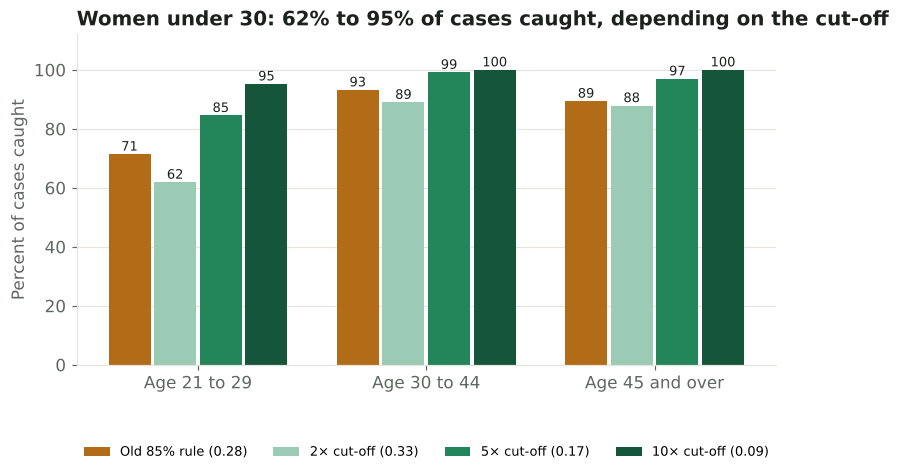

In [9]:
display(pd.DataFrame(m5["bands"]["calibration"]).set_index("band"))
figures.m5_bands();

**How to read it.** The table compares the average predicted risk with the real rate in each age band, and `slope` is the calibration slope (1.00 is ideal; below 1 means the risks are too extreme). The chart shows the share of each band's cases caught at the old 0.28 cut-off and at the three cost-based cut-offs.

**What it means.** The average predicted risk matches the real rate in every band (22% against 21% under 30, 48% against 49% for 30 to 44, 50% against 50% for 45 and over). The slope is 1.02, 0.91 and 0.77: the risks are right on average, but for women 45 and over they are somewhat too extreme, a hint that a shared cut-off is least precise there. Under 30 the old rule caught 71% of cases; the 5-times cut-off catches 85%, and the 10-times 95%. At 2 times it would be worse (62%), because a higher cut-off hurts the group whose risks are lowest. B12 is fixed by choosing the cut-off from a cost, not by adding age rules.

**What's next and why.** Test directly whether a cut-off per age band would do better still.

## 7.9 Separate cut-offs per age group

**What we're looking for.** Whether choosing a cut-off for each age band, on training women only, beats one shared cost-based cut-off.

In [10]:
rows = []
for r, v in m5["bands"]["by_ratio"].items():
    for name, pol in v["policies"].items():
        rows.append({"a missed case is": f"{r}x", "policy": name, "cost per 100": round(pol["cost_per_100"], 1),
                     "cut-offs (under 30 / 30-44 / 45+)": " / ".join(f"{b['cutoff']:.2f}" for b in pol["bands"]),
                     "caught under 30": f"{pol['bands'][0]['sensitivity']:.0%}"})
pd.DataFrame(rows).set_index(["a missed case is", "policy"])

cost per 100  \
a missed case is policy                                    
2x               Single cost-based cut-off        30.900   
                 Cheapest per band                30.000   
                 Catch 85% in every band          35.100   
5x               Single cost-based cut-off        40.500   
                 Cheapest per band                42.500   
                 Catch 85% in every band          51.600   
10x              Single cost-based cut-off        44.500   
                 Cheapest per band                47.700   
                 Catch 85% in every band          79.200   

                                           cut-offs (under 30 / 30-44 / 45+)  \
a missed case is policy                                                        
2x               Single cost-based cut-off                0.33 / 0.33 / 0.33   
                 Cheapest per band                        0.32 / 0.25 / 0.42   
                 Catch 85% in every band                  0.17 / 0.36 / 0.42   
5x               Single cost-based cut-off                0.17 / 0.17 / 0.17   
                 Cheapest per band                        0.12 / 0.24 / 0.09   
                 Catch 85% in every band                  0.17 / 0.36 / 0.42   
10x              Single cost-based cut-off                0.09 / 0.09 / 0.09   
                 Cheapest per band                        0.09 / 0.18 / 0.09   
                 Catch 85% in every band                  0.17 / 0.36 / 0.42   

                                           caught under 30  
a missed case is policy                                     
2x               Single cost-based cut-off             62%  
                 Cheapest per band                     60%  
                 Catch 85% in every band               83%  
5x               Single cost-based cut-off             85%  
                 Cheapest per band                     84%  
                 Catch 85% in every band               83%  
10x              Single cost-based cut-off             95%  
                 Cheapest per band                     93%  
                 Catch 85% in every band               83%

**How to read it.** Three policies, scored the honest way: each age band's cut-off is chosen on training women and used on test women, over the same 50 splits. `Single cost-based cut-off` is the formula, shared by every band. `Cheapest per band` picks the cheapest cut-off within each band. `Catch 85% in every band` is the old rule applied band by band.

**What it means.** One shared cut-off wins or ties. At 5 times it costs 40.5 against 42.5 for a cut-off per band; at 10 times 44.5 against 47.7; at 2 times the per-band version is 30.0 against 30.9, about one unit better, which is inside the noise. Catching 85% in every band is clearly worse (52 and 79 at 5 and 10 times), because it demands a cut-off of 0.42 for older women who are mostly cases anyway. With 66 to 118 cases per band, a cut-off fitted to one band mostly fits its noise. Decision D19: no age-specific cut-offs; E31 is closed as not needed.

**What's next and why.** Milestone 6 turns from deciding to explaining: why did the model give this woman this number?